# CHILLED - Chiller Health Indicator Learning & Early Detection

In [89]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pl.read_csv('output/chiller_data.csv')
print(df.shape)
print(df.schema)
root_df = df

(2508, 46)
Schema({'date': String, 'chiller_id': String, 'timestamp': String, 'refrigerant_leak_status': String, 'opening_of_vane': Float64, 'opening_hot_gas_bypass_valve': Float64, 'opening_of_2nd_vane': Float64, 'opening_of_high_stage_expansion_valve': Float64, 'opening_of_low_stage_expansion_valve': Float64, 'motor_voltage': Float64, 'motor_current': Float64, 'motor_input': Float64, 'compressor_running_time': Float64, 'compressor_suction_temperature': String, 'compressor_discharge_temperature': String, 'compressor_oil_tank_oil_temperature': Float64, 'compressor_oil_pressure': Float64, 'compressor_oil_level': String, 'compressor_oil_supply_temperature': Float64, 'evaporator_evaporating_pressure': Float64, 'evaporator_evaporating_temperature': Float64, 'evaporator_saturation_temperature': Float64, 'evaporator_approach_temp': Float64, 'evaporator_chilled_water_flow_rate': Float64, 'evaporator_chilled_water_entering_temperature': Float64, 'evaporator_chilled_water_leaving_temperature': 

In [3]:
pl.Config.set_tbl_rows(30)
df.head(15)

date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""2024-06-05""","""EC0120A""","""00:00""",null,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,null,null,57.9,5.2,null,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,null,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,null,5.52,null,null,null
"""2024-06-05""","""EC0120A""","""09:00""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,null,1225.3,0.0,null,null,null,null,null,null,null,null
"""2024-06-05""","""EC0120B""","""00:00""",null,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,null,null,59.2,0.49,null,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,null,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,null,5.23,null,null,null
"""2024-06-05""","""EC0120B""","""09:00""",null,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,null,null,59.2,4.49,null,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,null,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,null,4.76,null,null,null
"""2024-06-05""","""EC0120C""","""00:00""",null,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,null,null,58.0,0.59,null,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,null,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,null,5.33,null,null,null
"""2024-06-05""","""EC0120C""","""09:00""",null,71.2,0.0,67.6,62.6,37.1,6.6,115.2,1191.0,44240.0,null,null,58.2,0.59,null,45.1,0.23,4.8,3.9,-0.3,702.0,12.7,4.5,8.2,6647.113164,0.85,37.1,37.8,2.7,null,29.6,35.1,5.5,1297.0,8237.297921,0.47,20.1,203.2,null,5.08,null,null,null
"""2024-06-05""","""EC0120D""","""00:00""",null,73.5,0.1,68.1,64.9,35.2,6.6,118.6,1212.0,46445.0,null,null,57.5,0.54,null,44.7,0.23,4.7,3.6,0.3,701.4,13.2,5.0,8.2,6641.431871,0.86,38.0,38.3,3.4,null,29.2,34.9,5.7,1198.0,7885.2194,0.48,21.0,205.9,null,4.98,null,null,null
"""2024-06-05""","""EC0120D""","""09:00""",null,73.5,0.1,67.9,65.3,32.8,6.6,118.8,1215.0,46453.0,null,null,57.5,0.54,null,44.9,0.23,4.8,3.7,0.3,748.0,12.8,5.1,7.7,6650.808314,0.87,38.2,38.4,3.3,null,29.5,35.1,5.6,1220.0,7889.145497,0.49,21.2,217.4,null,4.68,null,null,null
"""2024-06-05""","""EC0120E""","""00:00""",null,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,0.0,null,0.0,null,null,null,null,null,null,null,null


In [4]:
df.describe()

statistic,date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""count""","""2508""","""2508""","""2508""","""1839""",1607.0,1607.0,1607.0,1607.0,1604.0,1671.0,1607.0,1607.0,1559.0,"""0""","""0""",1607.0,1605.0,"""2""",1605.0,1606.0,1604.0,1604.0,2459.0,1606.0,1606.0,1606.0,2471.0,2460.0,1606.0,1604.0,1605.0,2481.0,"""1""",1606.0,1606.0,2475.0,1607.0,2485.0,1606.0,1605.0,1606.0,"""0""",1606.0,"""2""","""0""","""24"""
"""null_count""","""0""","""0""","""0""","""669""",901.0,901.0,901.0,901.0,904.0,837.0,901.0,901.0,949.0,"""2508""","""2508""",901.0,903.0,"""2506""",903.0,902.0,904.0,904.0,49.0,902.0,902.0,902.0,37.0,48.0,902.0,904.0,903.0,27.0,"""2507""",902.0,902.0,33.0,901.0,23.0,902.0,903.0,902.0,"""2508""",902.0,"""2506""","""2508""","""2484"""
"""mean""",null,null,null,null,74.437772,0.140261,69.383199,69.491867,44.669264,7.020766,117.372222,1180.489172,49955.419949,null,null,58.207716,0.554841,null,44.996573,0.227634,4.126496,3.298211,0.946795,660.480679,13.302677,4.830822,5.500364,4143.824946,0.876164,36.109121,36.623925,1.796372,null,28.541968,33.894085,3.465737,1258.417554,4999.1552,0.519875,19.809875,184.104134,null,5.4784,null,null,null
"""std""",null,null,null,null,3.373344,1.808525,4.76401,29.138334,10.998752,14.773625,4.965425,49.425639,24490.42669,null,null,1.677108,1.22032,null,1.600992,0.053015,0.465814,1.075358,10.137757,33.363716,2.976027,12.520819,11.118173,9164.744913,2.00961,1.200236,2.078188,2.246753,null,0.936305,1.056961,2.701266,71.83696,3925.033645,1.641825,4.496737,55.880966,null,0.282415,null,null,null
"""min""","""2024-06-05""","""EC0120A""","""00:00""","""2028-11-12 09:36:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,null,null,44.5,0.43,"""m""",4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,""" """,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,null,4.54,"""5.75""",null,"""0"""
"""25%""",null,null,null,null,72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,null,null,57.7,0.49,null,44.9,0.22,3.9,2.9,0.0,637.8,13.0,4.2,0.0,0.0,0.81,35.6,36.2,0.0,null,28.0,33.4,0.0,1239.4,0.0,0.46,19.3,159.8,null,5.3,null,null,null
"""50%""",null,null,null,null,74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,null,null,58.4,0.52,null,45.0,0.22,4.2,3.3,0.8,648.6,13.3,4.5,8.4,6458.752887,0.82,36.2,36.7,2.2,null,28.6,33.9,5.1,1292.5,7518.12933,0.46,19.7,198.6,null,5.52,null,null,null
"""75%""",null,null,null,null,76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,null,null,59.0,0.53,null,45.1,0.23,4.4,3.6,1.2,677.92,13.5,4.8,8.9,6697.30254,0.84,36.7,37.3,2.9,null,29.0,34.4,5.

In [5]:
all_null_cols = [
    'compressor_suction_temperature',
    'compressor_discharge_temperature',
    'compressor_oil_level',
    'condensor_liquid_level_side_glass_bottom',
    'heat_balance',
    'pct_of_cooling_capacity',
    'pct_of_motor_input',
    'evaporator_metric_24'
]

df = df.drop(all_null_cols)

## Formatting
- timestamps
- chiller_id
- refrigerant_leak_status -> is_refrigerant_leak_healthy (bool)

In [6]:
df = df.with_columns(
    (pl.col('date') + " " + pl.col('timestamp'))
    .str.to_datetime("%Y-%m-%d %H:%M")
    .alias("timestamp")
)

df = df.drop('date')

In [7]:
df = df.with_columns(
    pl.col('chiller_id').str.tail(1)
)

In [8]:
df = df.with_columns(
    pl.when(pl.col('refrigerant_leak_status') == "OK")
        .then(1)
        .otherwise(0)
        .alias('is_refrigerant_leak_healthy (bool)')
)

df = df.drop('refrigerant_leak_status')

In [9]:
df.head()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""A""",2024-06-05 00:00:00,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,57.9,5.2,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,5.52,0
"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
"""B""",2024-06-05 00:00:00,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,59.2,0.49,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,5.23,0
"""B""",2024-06-05 09:00:00,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,59.2,4.49,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,4.76,0
"""C""",2024-06-05 00:00:00,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,58.0,0.59,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,5.33,0


## Columns with approx 900 null values

In [10]:
df.null_count()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,901,901,901,901,904,837,901,901,949,901,903,903,902,904,904,49,902,902,902,37,48,902,904,903,27,902,902,33,901,23,902,903,902,902,0


In [11]:
# Check if null values coincide

null_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'motor_current',
    'motor_input',
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_cooling_water_flow_rate',
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
    'cop'
]   # your similar-count null_cols

# Are the null masks identical across all these columns?
masks = df.select([pl.col(c).is_null().alias(c) for c in null_cols])

# rows where ALL are null vs rows where ANY is null
summary = df.select(
    n_all_null = pl.all_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
    n_any_null = pl.any_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
)
print(summary)

shape: (1, 2)
┌────────────┬────────────┐
│ n_all_null ┆ n_any_null │
│ ---        ┆ ---        │
│ u32        ┆ u32        │
╞════════════╪════════════╡
│ 894        ┆ 966        │
└────────────┴────────────┘


In [12]:
df.filter(pl.all_horizontal(pl.col(c).is_null() for c in null_cols)) \
  .select(["timestamp", "chiller_id"]) \
  .head(50)

timestamp,chiller_id
datetime[μs],str
2024-06-05 00:00:00,"""E"""
2024-06-05 09:00:00,"""E"""
2024-06-05 09:00:00,"""F"""
2024-06-06 09:00:00,"""C"""
2024-06-06 09:00:00,"""D"""
2024-06-06 00:00:00,"""E"""
2024-06-06 09:00:00,"""E"""
2024-06-07 09:00:00,"""A"""
2024-06-07 09:00:00,"""B"""


In [13]:
dup = df.drop(["timestamp", "chiller_id"])
dup = dup.filter(dup.is_duplicated())
dup_counts = dup.group_by(pl.all()).len().sort("len", descending=True)
dup_counts.select('len', pl.exclude('len'))

len,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
485,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
224,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
45,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,0
41,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
21,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0
19,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
16,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
14,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,1
6,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0


The vast majority of duplicate rows are the ones where the identified columns are null. Also when a row almost contains only null values, the entry doesn't carry enough information and is assumed to be an empty record actually. The rows with a lot of null values are dropped.

In [14]:
df = df.filter(~pl.all_horizontal(pl.col(c).is_null() for c in null_cols))

There are still a few cols that have a lot of null values

In [15]:
df.describe()

statistic,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""1614""","""1614""",1607.0,1607.0,1607.0,1607.0,1604.0,1606.0,1607.0,1607.0,1559.0,1607.0,1605.0,1605.0,1606.0,1604.0,1604.0,1609.0,1606.0,1606.0,1606.0,1612.0,1597.0,1606.0,1604.0,1605.0,1613.0,1606.0,1606.0,1611.0,1607.0,1614.0,1606.0,1605.0,1606.0,1606.0,1614.0
"""null_count""","""0""","""0""",7.0,7.0,7.0,7.0,10.0,8.0,7.0,7.0,55.0,7.0,9.0,9.0,8.0,10.0,10.0,5.0,8.0,8.0,8.0,2.0,17.0,8.0,10.0,9.0,1.0,8.0,8.0,3.0,7.0,0.0,8.0,9.0,8.0,8.0,0.0
"""mean""",null,"""2024-12-29 21:49:57.769516""",74.437772,0.140261,69.383199,69.491867,44.669264,7.037796,117.372222,1180.489172,49955.419949,58.207716,0.554841,44.996573,0.227634,4.126496,3.298211,1.446967,660.480679,13.302677,4.830822,8.43139,6383.099166,0.876164,36.109121,36.623925,2.725232,28.541968,33.894085,5.324457,1258.417554,7696.964481,0.519875,19.809875,184.104134,5.4784,0.975217
"""std""",null,null,3.373344,1.808525,4.76401,29.138334,10.998752,15.069563,4.965425,49.425639,24490.42669,1.677108,1.22032,1.600992,0.053015,0.465814,1.075358,12.505081,33.363716,2.976027,12.520819,12.83736,10728.798065,2.00961,1.200236,2.078188,2.294167,0.936305,1.056961,1.144481,71.83696,1716.701054,1.641825,4.496737,55.880966,0.282415,0.155512
"""min""","""A""","""2024-06-05 00:00:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,44.5,0.43,4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,4.54,0.0
"""25%""",null,"""2024-07-25 09:00:00""",72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,57.7,0.49,44.9,0.22,3.9,2.9,0.8,637.8,13.0,4.2,8.4,6473.152425,0.81,35.6,36.2,2.2,28.0,33.4,5.2,1239.4,7552.369515,0.46,19.3,159.8,5.3,1.0
"""50%""",null,"""2025-03-15 00:00:00""",74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,58.4,0.52,45.0,0.22,4.2,3.3,1.1,648.6,13.3,4.5,8.8,6638.152425,0.82,36.2,36.7,2.6,28.6,33.9,5.4,1292.5,7885.450346,0.46,19.7,198.6,5.52,1.0
"""75%""",null,"""2025-05-11 00:00:00""",76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,59.0,0.53,45.1,0.23,4.4,3.6,1.4,677.92,13.5,4.8,9.0,6788.048499,0.84,36.7,37.3,3.3,29.0,34.4,5.6,1297.8,8104.988453,0.47,20.1,205.6,5.67,1.0
"""max""","""F""","""2025-06-30 09:00:00""",83.9,72.2,81.0,739.0,100.0,606.0,196.9,1243.0,495779.0,62.4,49.0,59.6,2.2,5.5,36.5,501.9,768.8,131.3,506.0,126.7,94009.644342,81.0,38.8,63.2,31.9,39.5,36.5,7.9,1361.7,11527.431871,47.0,196.5,2000.8,6.32,1.0


In [16]:
n_nulls_df = df.with_columns(
    pl.sum_horizontal(pl.all().is_null()).alias('n_nulls')
)

n_nulls_df.select("n_nulls", pl.exclude("n_nulls")).sort('n_nulls', descending=True)

n_nulls,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
28,"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
28,"""A""",2024-07-23 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,1
27,"""A""",2024-07-24 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,0
27,"""D""",2025-04-03 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.11,1
27,"""D""",2025-04-22 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1293.74,0.0,null,null,null,null,0
27,"""E""",2025-04-29 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1246.0,0.0,null,null,null,null,0
17,"""A""",2025-03-14 00:00:00,70.6,0.1,64.7,67.4,36.2,6.6,117.2,1147.0,49077.0,58.5,0.53,null,null,null,null,0.3,null,null,null,8.4,6286.226328,null,null,null,2.6,null,null,5.9,null,7484.551963,null,null,null,null,1
17,"""B""",2025-05-02 00:00:00,77.3,0.0,72.1,68.8,54.7,6.6,114.7,1166.0,51293.0,59.1,0.49,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
11,"""B""",2025-03-14 09:00:00,null,null,null,null,null,null,null,null,null,null,null,44.7,0.22,4.2,3.2,2.1,646.7,13.7,5.5,8.3,6282.69746,0.83,36.1,36.9,4.1,28.3,33.4,4.8,1226.2,7206.540416,0.46,19.7,119.8,5.41,1


There a few more rows with rather sparse data. We're also dropping those since they don't carry much information and because there values don't seem to be out of the ordinary

In [17]:
df = df.filter(pl.sum_horizontal(pl.all().is_null()) < 2)

In [18]:
df.shape

(1601, 37)

This leaves us with a dataset of 1601 datapoints and 37 sensor measurments

## Visualizations

In [19]:
df.columns

['chiller_id',
 'timestamp',
 'opening_of_vane',
 'opening_hot_gas_bypass_valve',
 'opening_of_2nd_vane',
 'opening_of_high_stage_expansion_valve',
 'opening_of_low_stage_expansion_valve',
 'motor_voltage',
 'motor_current',
 'motor_input',
 'compressor_running_time',
 'compressor_oil_tank_oil_temperature',
 'compressor_oil_pressure',
 'compressor_oil_supply_temperature',
 'evaporator_evaporating_pressure',
 'evaporator_evaporating_temperature',
 'evaporator_saturation_temperature',
 'evaporator_approach_temp',
 'evaporator_chilled_water_flow_rate',
 'evaporator_chilled_water_entering_temperature',
 'evaporator_chilled_water_leaving_temperature',
 'evaporator_temperature_difference',
 'evaporator_chilling_capacity',
 'condensor_condensing_pressure',
 'condensor_consensed_liquid_temperature',
 'condensor_saturated_temeprature',
 'condensor_approach_temp_cond_lq_temp_leaving_temp',
 'condensor_cooling_water_entering_temperature',
 'condensor_cooling_water_leaving_temperature',
 'condenso

In [27]:
df

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""A""",2024-06-05 00:00:00,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,57.9,5.2,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,5.52,0
"""B""",2024-06-05 00:00:00,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,59.2,0.49,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,5.23,0
"""B""",2024-06-05 09:00:00,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,59.2,4.49,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,4.76,0
"""C""",2024-06-05 00:00:00,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,58.0,0.59,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,5.33,0
"""C""",2024-06-05 09:00:00,71.2,0.0,67.6,62.6,37.1,6.6,115.2,1191.0,44240.0,58.2,0.59,45.1,0.23,4.8,3.9,-0.3,702.0,12.7,4.5,8.2,6647.113164,0.85,37.1,37.8,2.7,29.6,35.1,5.5,1297.0,8237.297921,0.47,20.1,203.2,5.08,0
"""D""",2024-06-05 00:00:00,73.5,0.1,68.1,64.9,35.2,6.6,118.6,1212.0,46445.0,57.5,0.54,44.7,0.23,4.7,3.6,0.3,701.4,13.2,5.0,8.2,6641.431871,0.86,38.0,38.3,3.4,29.2,34.9,5.7,1198.0,7885.2194,0.48,21.0,205.9,4.98,0
"""D""",2024-06-05 09:00:00,73.5,0.1,67.9,65.3,32.8,6.6,118.8,1215.0,46453.0,57.5,0.54,44.9,0.23,4.8,3.7,0.3,748.0,12.8,5.1,7.7,6650.808314,0.87,38.2,38.4,3.3,29.5,35.1,5.6,1220.0,7889.145497,0.49,21.2,217.4,4.68,0
"""F""",2024-06-05 00:00:00,78.6,0.2,73.8,70.9,42.4,6.6,120.0,1221.0,47572.8,59.4,0.48,44.8,0.22,4.3,3.7,0.8,687.0,13.3,5.1,8.2,6505.080831,0.84,37.1,37.3,2.3,29.1,35.0,5.9,1215.0,8277.713626,0.47,20.4,203.1,4.89,0
"""A""",2024-06-06 00:00:00,71.7,0.8,66.2,64.9,56.8,6.6,117.0,1159.0,45697.9,58.1,0.53,44.8,0.23,4.4,4.1,0.5,703.1,13.3,4.9,8.4,6819.907621,0.84,37.2,37.4,1.9,29.7,35.3,5.6,1221.7,7900.138568,0.48,20.5,217.7,5.47,1


In [30]:
df.columns

['chiller_id',
 'timestamp',
 'opening_of_vane',
 'opening_hot_gas_bypass_valve',
 'opening_of_2nd_vane',
 'opening_of_high_stage_expansion_valve',
 'opening_of_low_stage_expansion_valve',
 'motor_voltage',
 'motor_current',
 'motor_input',
 'compressor_running_time',
 'compressor_oil_tank_oil_temperature',
 'compressor_oil_pressure',
 'compressor_oil_supply_temperature',
 'evaporator_evaporating_pressure',
 'evaporator_evaporating_temperature',
 'evaporator_saturation_temperature',
 'evaporator_approach_temp',
 'evaporator_chilled_water_flow_rate',
 'evaporator_chilled_water_entering_temperature',
 'evaporator_chilled_water_leaving_temperature',
 'evaporator_temperature_difference',
 'evaporator_chilling_capacity',
 'condensor_condensing_pressure',
 'condensor_consensed_liquid_temperature',
 'condensor_saturated_temeprature',
 'condensor_approach_temp_cond_lq_temp_leaving_temp',
 'condensor_cooling_water_entering_temperature',
 'condensor_cooling_water_leaving_temperature',
 'condenso

In [32]:
valve_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'opening_of_low_stage_expansion_valve'
]

motor_cols = [
    'motor_voltage',
    'motor_current',
    'motor_input',
]

compressor_cols = [
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
]

evaporator_cols = [
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_approach_temp',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'evaporator_temperature_difference',
    'evaporator_chilling_capacity',
]

condensor_cols = [
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_approach_temp_cond_lq_temp_leaving_temp',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_temperature_difference_cooling_water',
    'condensor_cooling_water_flow_rate',
    'condensor_heat_capacity',
]

economizer_cols = [
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
]

other_cols = [
    'cop',
    'is_refrigerant_leak_healthy (bool)'
]

sensor_groups = {
    "valves": valve_cols,
    "motor": motor_cols,
    "compressor": compressor_cols,
    "evaporator": evaporator_cols,
    "condensor": condensor_cols,
    "economizer": economizer_cols,
    "other": other_cols,
}

In [40]:
pdf = long.sort("timestamp").to_pandas()
print(pdf.dtypes)
print(type(pdf["timestamp"].iloc[0]))

timestamp     datetime64[us]
chiller_id               str
sensor                   str
value                float64
dtype: object
<class 'pandas.Timestamp'>


In [115]:
def plot_group(df, name, cols):
    long = df.filter(pl.col("chiller_id") == "B").unpivot(
        index=["timestamp", "chiller_id"],
        on=cols,
        variable_name="sensor",
        value_name="value",
    )
    
    long = long.with_columns(
        pl.when(pl.col("timestamp") < pl.datetime(2024, 9, 1))
        .then(pl.lit("JUN-AUG"))
        .otherwise(pl.lit("APR-MAY"))
        .alias("period")
    )
    
    n = len(cols)
    fig = px.line(
        long.sort("timestamp").to_pandas(),
        x="timestamp", y="value",
        facet_row="sensor",
        facet_col="period",
        color="chiller_id",
        facet_row_spacing=min(0.02, 1 / (n * 2)),   # safe for any group size
        height=max(400, 180 * n),
        title=f"{name} sensors",
    )
    
    
    fig.update_yaxes(matches=None)  
    
    fig.update_xaxes(matches=None)
    fig.update_xaxes(range=["2024-06-01", "2024-08-31"], col=1)
    fig.update_xaxes(range=["2025-03-01", "2025-05-31"], col=2)# independent y-scales
    
    row_anns = [a for a in fig.layout.annotations if a.textangle == 90]

    for i, a in enumerate(row_anns):
        a.update(
            text=a.text.split("=")[-1],
            font_size=10,
            xshift=15 if i % 2 else 5,   # push every second label further right
        )
    
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
    
    fig.update_layout(margin=dict(t=110))
    
    fig.show()

for name, cols in sensor_groups.items():
    plot_group(df, name, cols)

In [113]:
sensor_cols = [c for c, t in df.schema.items() if c not in ("timestamp", "chiller_id") and t in (pl.Float64, pl.Int64)]

corr = df.filter(pl.col("chiller_id") == "E").select(sensor_cols).drop_nulls().corr()

In [93]:
df.select([pl.col(c).is_null().sum().alias(c) for c in sensor_cols])

opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,2,1,0,0,48,0,1,1,0,1,2,3,0,0,0,1,16,0,1,1,1,0,0,1,2,0,0,1,0,3


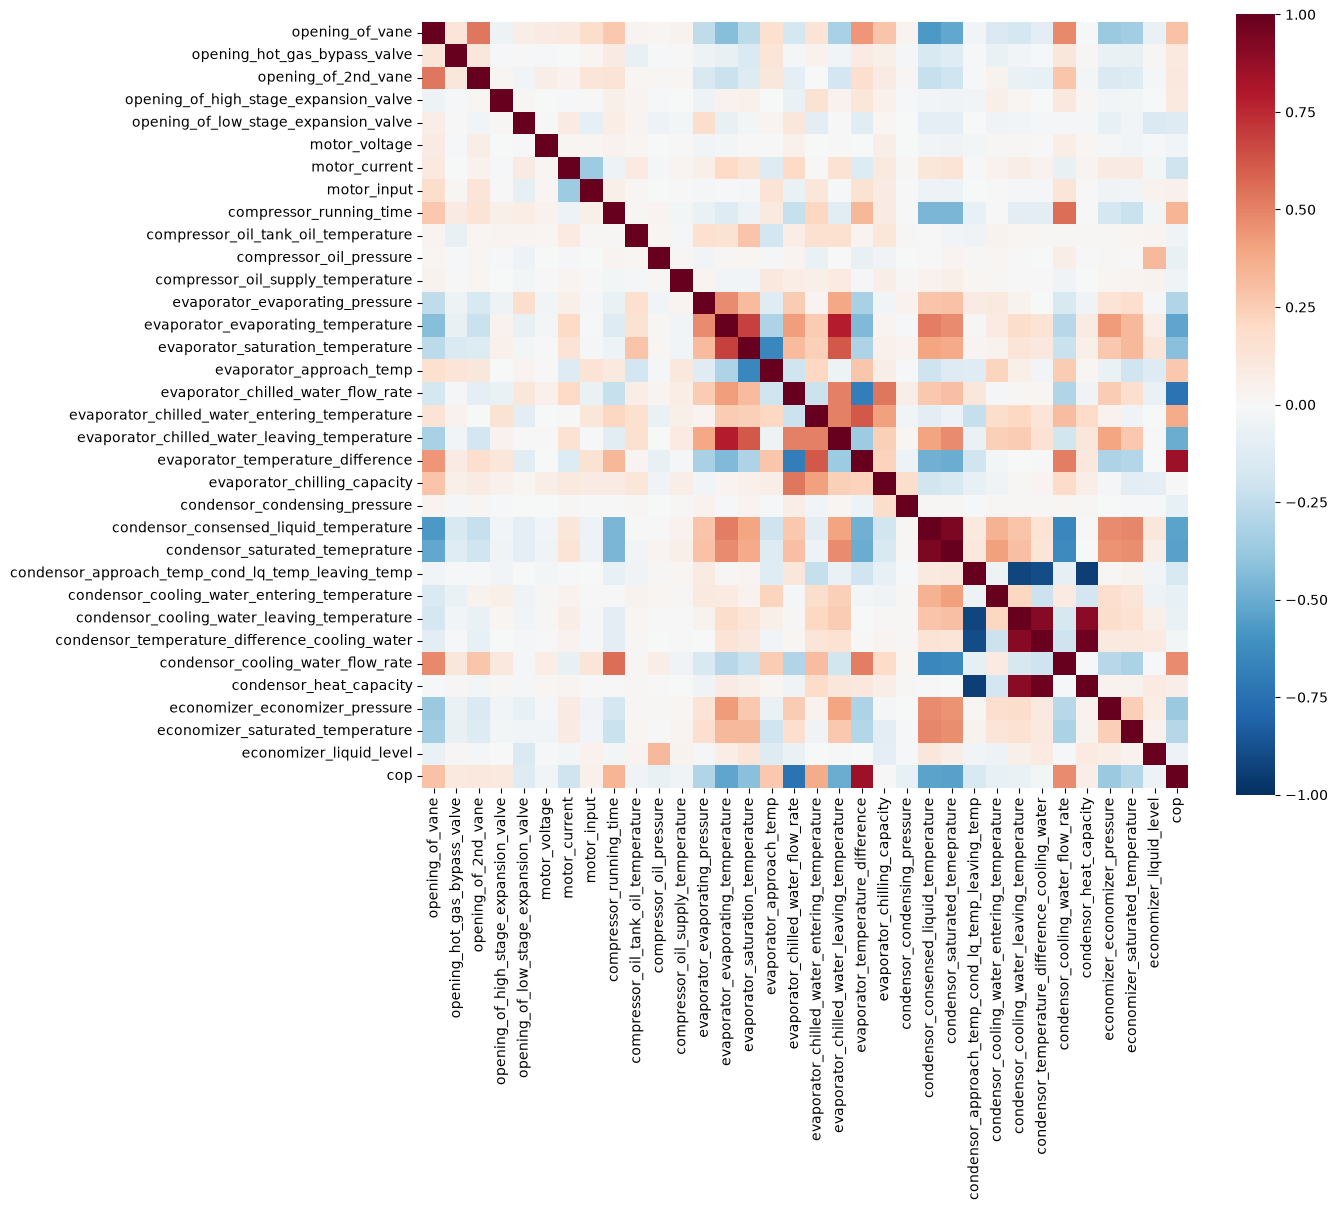

In [114]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()

In [105]:
z = df.drop_nulls().with_columns([
    ((pl.col(c) - pl.col(c).mean().over("chiller_id"))
        / pl.col(c).std().over("chiller_id")).alias(c)
    for c in sensor_cols
])
z_corr = z.select(sensor_cols).corr()

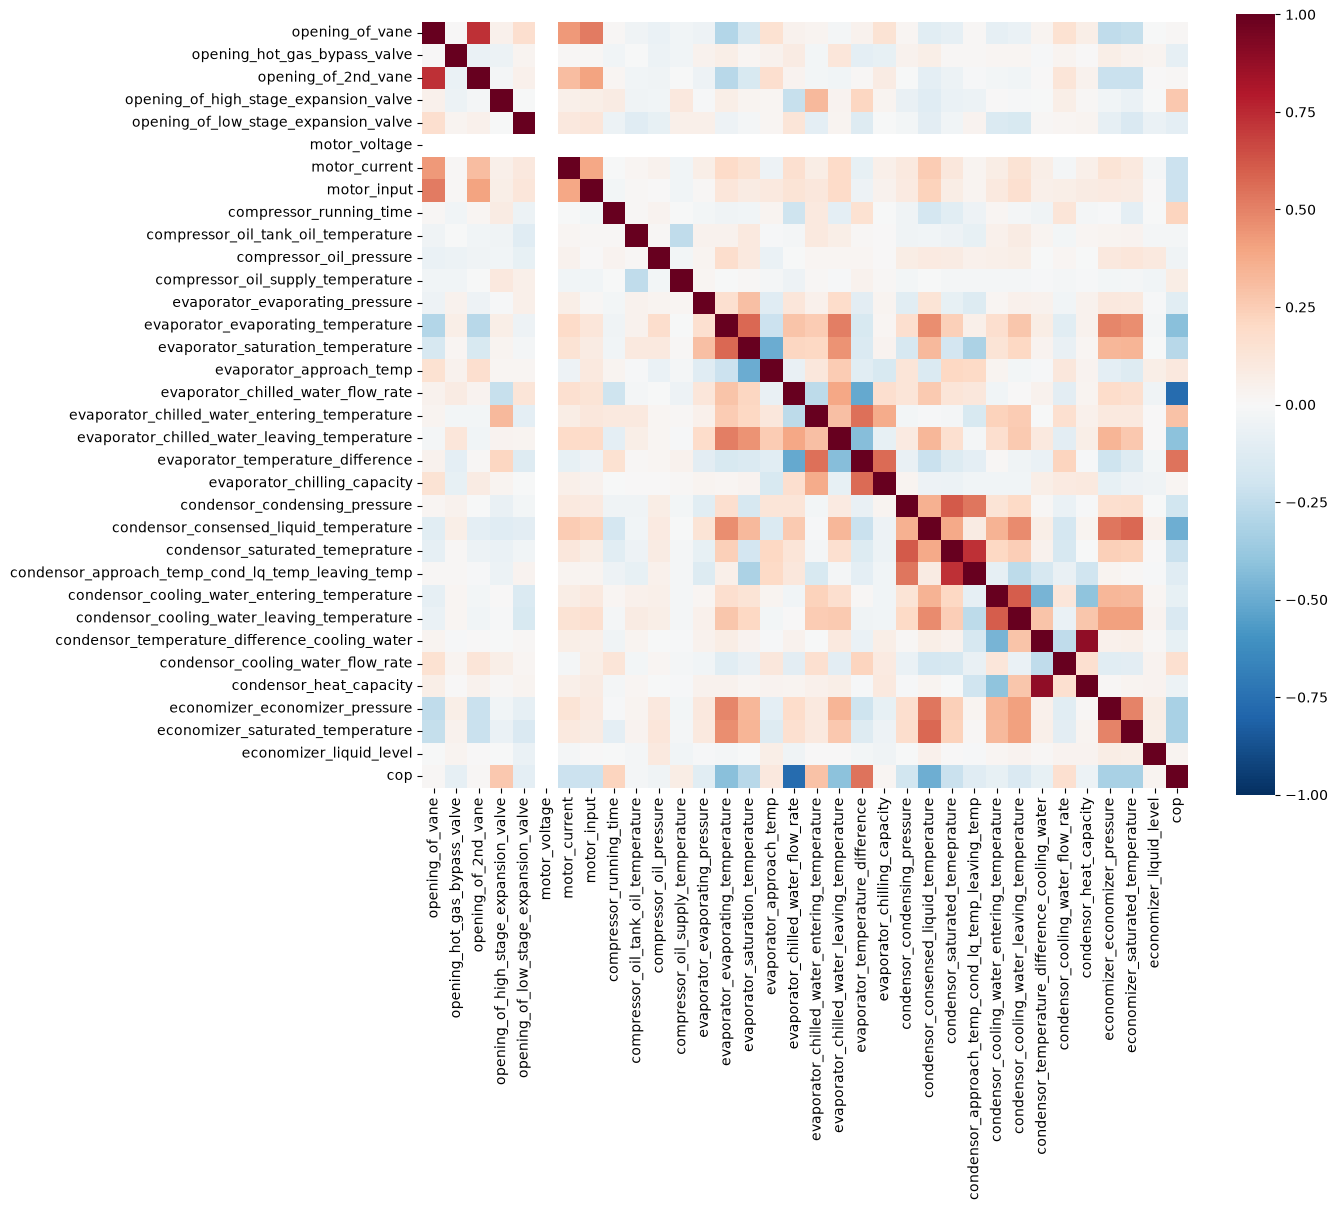

In [106]:
plt.figure(figsize=(14, 12))
sns.heatmap(z_corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()